# SND@LHC Reference Time Distributions Analysis
This notebook analyzes and plots the event reference time distributions (**`reft-SF`** and **`reft-DS`**) for:
- **Category II runs (2022)**: 33 qualifying collision physics runs with >3M entries and non-zero luminosity.
- **Category III runs (2023–2025)**: Top 10 collision physics runs by entries for each year (30 runs total).

All histograms are retrieved from `/eos/user/i/idioniso/Timing/ref_times/runs/run<RUN>.root`.


In [1]:
import os
import glob
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit
import uproot

# Try importing CERN / ddfUtils custom styling if available
try:
    import ddfUtils.mpl_styling as dms
    dms.set_style()
except Exception:
    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

RUNS_DIR = "/eos/user/i/idioniso/Timing/ref_times/runs"
REPO_ROOT = "/afs/cern.ch/work/i/idioniso/snd-veto-us"

# 1. Identify qualifying available runs
available_files = sorted(glob.glob(f"{RUNS_DIR}/run*.root"))
avail_runs = set(int(os.path.basename(f).replace("run", "").replace(".root", "")) for f in available_files)

# Category II runs (2022)
df_2022 = pd.read_csv(f"{REPO_ROOT}/runs_2022.csv")
c2_mask = (
    df_2022['category'].str.strip().str.upper().isin(['II', 'CATII']) &
    (df_2022['entries'] > 3000000) &
    (df_2022['luminosity_pb'] > 0) &
    (df_2022['is_physics_collision'] == True)
)
catII_runs = sorted(list(set(df_2022[c2_mask]['run_number']).intersection(avail_runs)))

# Category III runs (2023-2025 top 10 per year)
catIII_runs_by_year = {}
for y in [2023, 2024, 2025]:
    csv_path = f"{REPO_ROOT}/runs_{y}.csv"
    if os.path.exists(csv_path):
        df_y = pd.read_csv(csv_path)
        mask_y = (df_y['is_physics_collision'] == True) & (df_y['luminosity_pb'] > 0)
        top10_y = df_y[mask_y].sort_values('entries', ascending=False).head(10)['run_number']
        r_y = sorted(list(set(top10_y).intersection(avail_runs)))
        if r_y:
            catIII_runs_by_year[y] = r_y

catIII_all_runs = sorted([r for yr_runs in catIII_runs_by_year.values() for r in yr_runs])
all_selected_runs = catII_runs + catIII_all_runs

print(f"[INFO] Loaded run selections from catalogs:")
print(f"  -> Category II (2022): {len(catII_runs)} runs (Runs {catII_runs[0]} - {catII_runs[-1]})")
for y, r_list in catIII_runs_by_year.items():
    print(f"  -> Category III ({y}): {len(r_list)} runs (Runs {r_list[0]} - {r_list[-1]})")
print(f"  -> Total Cat III runs: {len(catIII_all_runs)} runs")

# 2. Multithreaded loading of histograms
def load_run_histograms(run_nr):
    fpath = f"{RUNS_DIR}/run{run_nr}.root"
    try:
        with uproot.open(fpath) as f:
            v_sf, e_sf = f["reft-SF"].to_numpy()
            v_ds, e_ds = f["reft-DS"].to_numpy()
            return run_nr, v_sf, e_sf, v_ds, e_ds
    except Exception as e:
        print(f"[WARNING] Could not load run {run_nr}: {e}")
        return run_nr, None, None, None, None

with ThreadPoolExecutor(max_workers=12) as executor:
    loaded_results = list(executor.map(load_run_histograms, all_selected_runs))

hist_data = {
    r: {
        'sf_val': vs, 'sf_edges': es,
        'ds_val': vd, 'ds_edges': ed
    }
    for r, vs, es, vd, ed in loaded_results if vs is not None and vd is not None
}

print(f"[SUCCESS] Successfully loaded histograms for {len(hist_data)} / {len(all_selected_runs)} runs.")


[INFO] Loaded run selections from catalogs:
  -> Category II (2022): 33 runs (Runs 5119 - 5408)
  -> Category III (2023): 10 runs (Runs 6079 - 6667)
  -> Category III (2024): 10 runs (Runs 8638 - 9880)
  -> Category III (2025): 10 runs (Runs 11124 - 12217)
  -> Total Cat III runs: 30 runs


[SUCCESS] Successfully loaded histograms for 63 / 63 runs.


## 1. Reference Time Distributions for Category II Runs (2022)
Distribution of SciFi Reference Time ($t_0^{\mathrm{SF}}$) and DS Reference Time ($t_0^{\mathrm{DS}}$) across all Category II collision runs.
Run numbers are differentiated using the **`jet`** colormap.


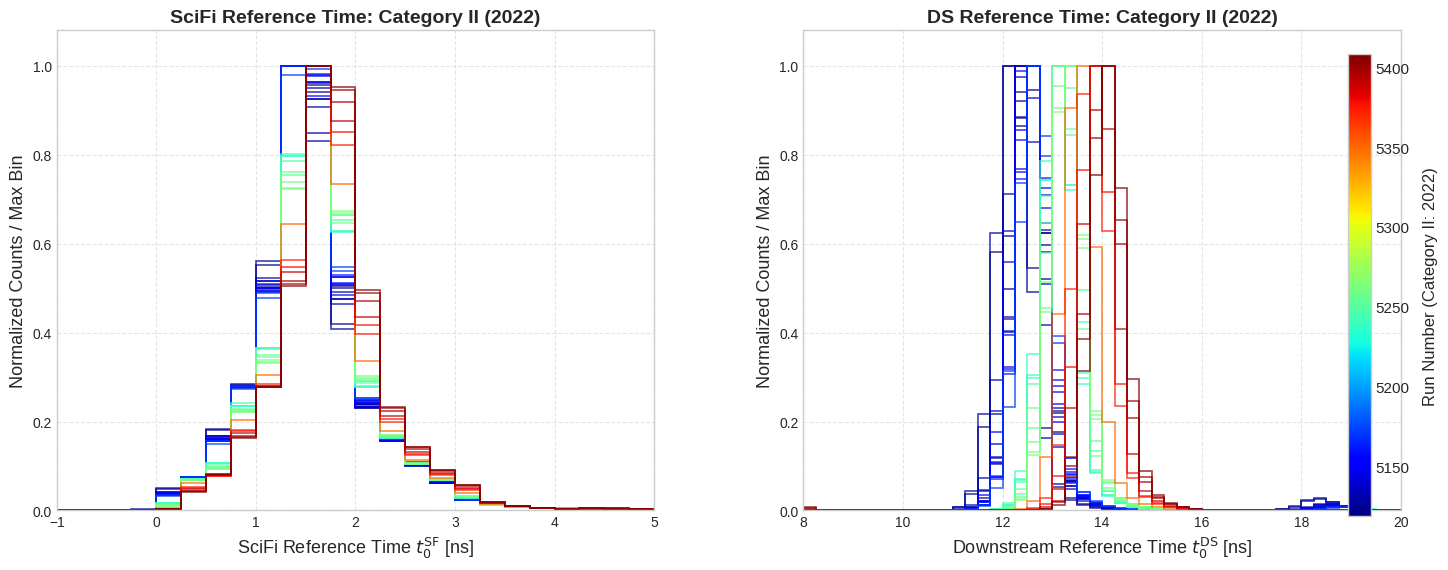

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

c2_min, c2_max = min(catII_runs), max(catII_runs)
norm_c2 = mcolors.Normalize(vmin=c2_min, vmax=c2_max)
cmap = cm.jet

for r in catII_runs:
    if r not in hist_data:
        continue
    d = hist_data[r]
    c = cmap(norm_c2(r))
    
    # Normalize each run histogram to unit peak for shape comparison
    max_sf = np.max(d['sf_val']) if np.max(d['sf_val']) > 0 else 1.0
    max_ds = np.max(d['ds_val']) if np.max(d['ds_val']) > 0 else 1.0
    
    bc_sf = 0.5 * (d['sf_edges'][:-1] + d['sf_edges'][1:])
    bc_ds = 0.5 * (d['ds_edges'][:-1] + d['ds_edges'][1:])
    
    ax1.stairs(d['sf_val'] / max_sf, d['sf_edges'], color=c, lw=1.2, alpha=0.75)
    ax2.stairs(d['ds_val'] / max_ds, d['ds_edges'], color=c, lw=1.2, alpha=0.75)

# Styling Subplot 1 (SciFi Reference Time)
ax1.set_xlim(-1.0, 5.0)
ax1.set_ylim(0, 1.08)
ax1.set_xlabel(r"SciFi Reference Time $t_0^{\mathrm{SF}}$ [ns]", fontsize=13)
ax1.set_ylabel("Normalized Counts / Max Bin", fontsize=13)
ax1.set_title("SciFi Reference Time: Category II (2022)", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle="--", alpha=0.5)

# Styling Subplot 2 (DS Reference Time)
ax2.set_xlim(8.0, 20.0)
ax2.set_ylim(0, 1.08)
ax2.set_xlabel(r"Downstream Reference Time $t_0^{\mathrm{DS}}$ [ns]", fontsize=13)
ax2.set_ylabel("Normalized Counts / Max Bin", fontsize=13)
ax2.set_title("DS Reference Time: Category II (2022)", fontsize=14, fontweight='bold')
ax2.grid(True, linestyle="--", alpha=0.5)

# Add Colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm_c2)
sm.set_array([])
cbar = fig.colorbar(sm, ax=[ax1, ax2], orientation='vertical', fraction=0.03, pad=0.03)
cbar.set_label("Run Number (Category II: 2022)", fontsize=12, labelpad=10)
cbar.ax.tick_params(labelsize=11)

plt.subplots_adjust(top=0.92, bottom=0.12, left=0.07, right=0.91, wspace=0.25)
plt.show()


## 2. Reference Time Distributions for Category III Runs (2023–2025 All Together)
Distribution of SciFi Reference Time ($t_0^{\mathrm{SF}}$) and DS Reference Time ($t_0^{\mathrm{DS}}$) across all Category III runs together.
Run numbers are differentiated using the **`jet`** colormap across the full 2023–2025 run range.


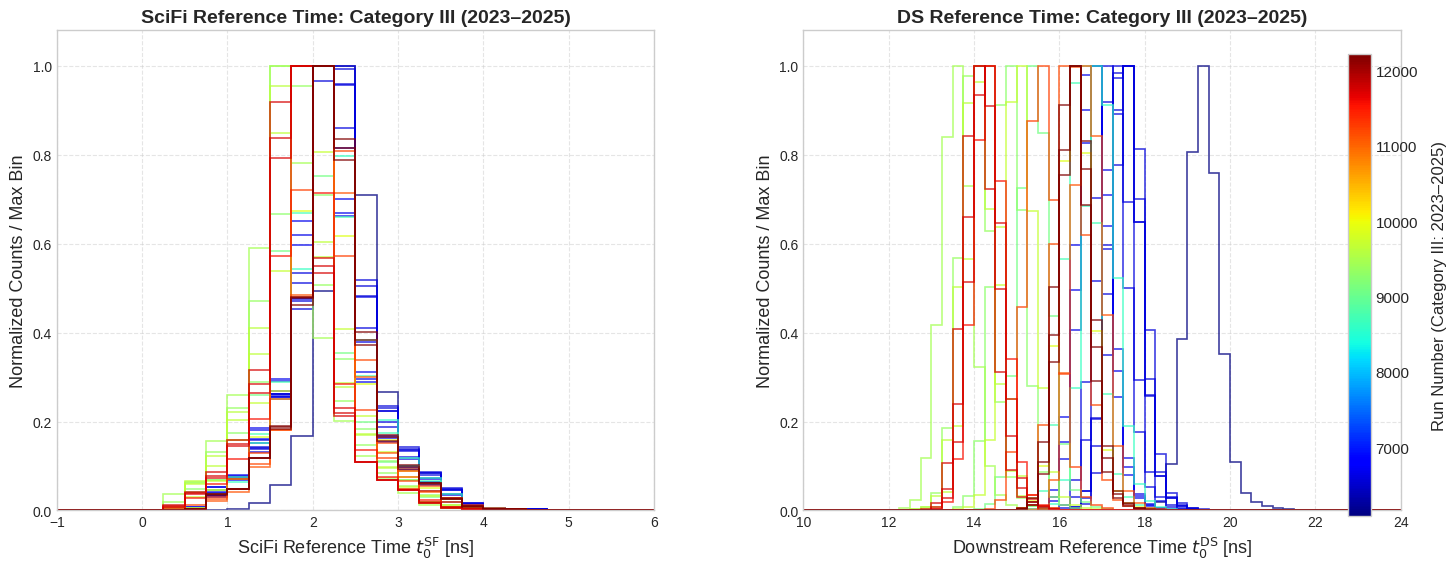

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

c3_min, c3_max = min(catIII_all_runs), max(catIII_all_runs)
norm_c3 = mcolors.Normalize(vmin=c3_min, vmax=c3_max)
cmap = cm.jet

for r in catIII_all_runs:
    if r not in hist_data:
        continue
    d = hist_data[r]
    c = cmap(norm_c3(r))
    
    max_sf = np.max(d['sf_val']) if np.max(d['sf_val']) > 0 else 1.0
    max_ds = np.max(d['ds_val']) if np.max(d['ds_val']) > 0 else 1.0
    
    bc_sf = 0.5 * (d['sf_edges'][:-1] + d['sf_edges'][1:])
    bc_ds = 0.5 * (d['ds_edges'][:-1] + d['ds_edges'][1:])
    
    ax1.stairs(d['sf_val'] / max_sf, d['sf_edges'], color=c, lw=1.2, alpha=0.75)
    ax2.stairs(d['ds_val'] / max_ds, d['ds_edges'], color=c, lw=1.2, alpha=0.75)

# Styling Subplot 1 (SciFi Reference Time)
ax1.set_xlim(-1.0, 6.0)
ax1.set_ylim(0, 1.08)
ax1.set_xlabel(r"SciFi Reference Time $t_0^{\mathrm{SF}}$ [ns]", fontsize=13)
ax1.set_ylabel("Normalized Counts / Max Bin", fontsize=13)
ax1.set_title("SciFi Reference Time: Category III (2023–2025)", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle="--", alpha=0.5)

# Styling Subplot 2 (DS Reference Time)
ax2.set_xlim(10.0, 24.0)
ax2.set_ylim(0, 1.08)
ax2.set_xlabel(r"Downstream Reference Time $t_0^{\mathrm{DS}}$ [ns]", fontsize=13)
ax2.set_ylabel("Normalized Counts / Max Bin", fontsize=13)
ax2.set_title("DS Reference Time: Category III (2023–2025)", fontsize=14, fontweight='bold')
ax2.grid(True, linestyle="--", alpha=0.5)

# Add Colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm_c3)
sm.set_array([])
cbar = fig.colorbar(sm, ax=[ax1, ax2], orientation='vertical', fraction=0.03, pad=0.03)
cbar.set_label("Run Number (Category III: 2023–2025)", fontsize=12, labelpad=10)
cbar.ax.tick_params(labelsize=11)

plt.subplots_adjust(top=0.92, bottom=0.12, left=0.07, right=0.91, wspace=0.25)
plt.show()


## 3. Category III Runs by Year in Columnar Form
Subfigures arranged column-wise for each Category III year (**2023**, **2024**, and **2025**):
- **Row 1**: SciFi Reference Time ($t_0^{\mathrm{SF}}$)
- **Row 2**: Downstream Reference Time ($t_0^{\mathrm{DS}}$)
Each column applies the **`jet`** colormap scaled to that year's run range.


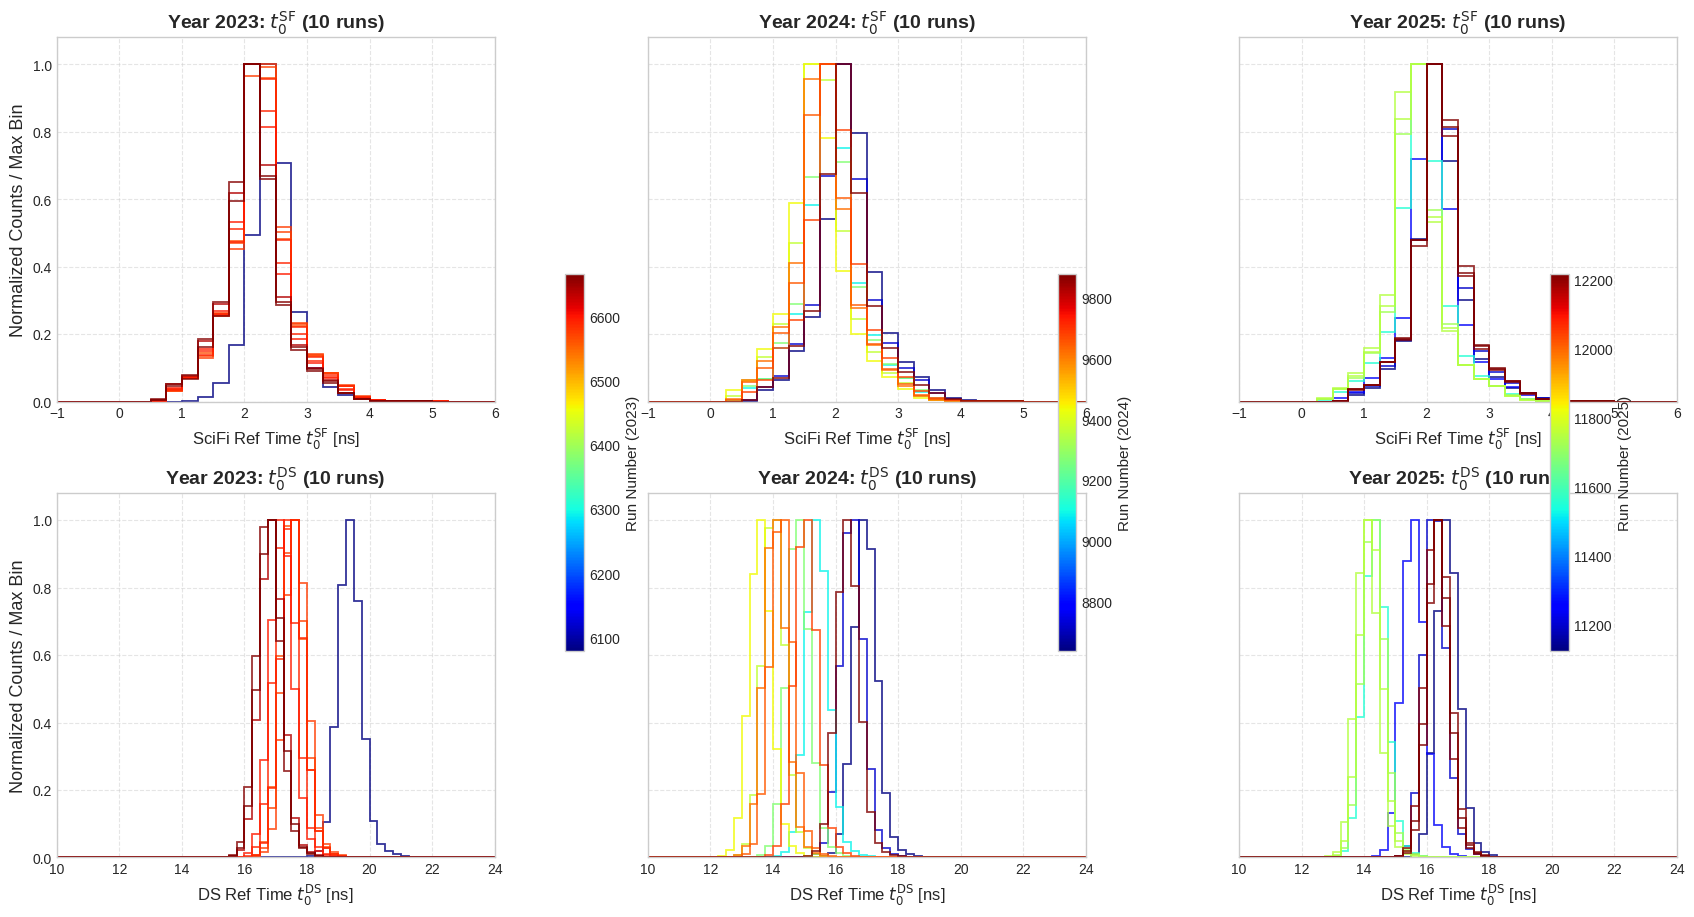

In [4]:
years = sorted(list(catIII_runs_by_year.keys()))
n_cols = len(years)

fig, axes = plt.subplots(2, n_cols, figsize=(6 * n_cols, 10), sharey=True)

for col_idx, yr in enumerate(years):
    yr_runs = catIII_runs_by_year[yr]
    norm_yr = mcolors.Normalize(vmin=min(yr_runs), vmax=max(yr_runs))
    
    ax_sf = axes[0, col_idx]
    ax_ds = axes[1, col_idx]
    
    for r in yr_runs:
        if r not in hist_data:
            continue
        d = hist_data[r]
        c = cm.jet(norm_yr(r))
        
        max_sf = np.max(d['sf_val']) if np.max(d['sf_val']) > 0 else 1.0
        max_ds = np.max(d['ds_val']) if np.max(d['ds_val']) > 0 else 1.0
        
        bc_sf = 0.5 * (d['sf_edges'][:-1] + d['sf_edges'][1:])
        bc_ds = 0.5 * (d['ds_edges'][:-1] + d['ds_edges'][1:])
        
        ax_sf.stairs(d['sf_val'] / max_sf, d['sf_edges'], color=c, lw=1.3, alpha=0.8)
        ax_ds.stairs(d['ds_val'] / max_ds, d['ds_edges'], color=c, lw=1.3, alpha=0.8)
        
    ax_sf.set_xlim(-1.0, 6.0)
    ax_sf.set_ylim(0, 1.08)
    ax_sf.set_title(f"Year {yr}: $t_0^{{\mathrm{{SF}}}}$ ({len(yr_runs)} runs)", fontsize=14, fontweight='bold')
    ax_sf.set_xlabel(r"SciFi Ref Time $t_0^{\mathrm{SF}}$ [ns]", fontsize=12)
    ax_sf.grid(True, linestyle="--", alpha=0.5)
    if col_idx == 0:
        ax_sf.set_ylabel("Normalized Counts / Max Bin", fontsize=13)
        
    ax_ds.set_xlim(10.0, 24.0)
    ax_ds.set_ylim(0, 1.08)
    ax_ds.set_title(f"Year {yr}: $t_0^{{\mathrm{{DS}}}}$ ({len(yr_runs)} runs)", fontsize=14, fontweight='bold')
    ax_ds.set_xlabel(r"DS Ref Time $t_0^{\mathrm{DS}}$ [ns]", fontsize=12)
    ax_ds.grid(True, linestyle="--", alpha=0.5)
    if col_idx == 0:
        ax_ds.set_ylabel("Normalized Counts / Max Bin", fontsize=13)
        
    # Column-level vertical Colorbar on the right
    sm_yr = cm.ScalarMappable(cmap=cm.jet, norm=norm_yr)
    sm_yr.set_array([])
    cbar = fig.colorbar(sm_yr, ax=[ax_sf, ax_ds], orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label(f"Run Number ({yr})", fontsize=11)
    cbar.ax.tick_params(labelsize=10)

plt.subplots_adjust(top=0.92, bottom=0.10, left=0.06, right=0.96, wspace=0.35, hspace=0.25)
plt.show()


## 4. Unified Reference Time Distributions (Summed by Category & Year)
All run histograms within each category and year are summed together:
- **Category II (2022)** (33 runs)
- **Category III (2023)** (10 runs)
- **Category III (2024)** (10 runs)
- **Category III (2025)** (10 runs)
A Gaussian peak fit is performed on each unified distribution to extract the precise peak position $\mu$ and resolution $\sigma$.


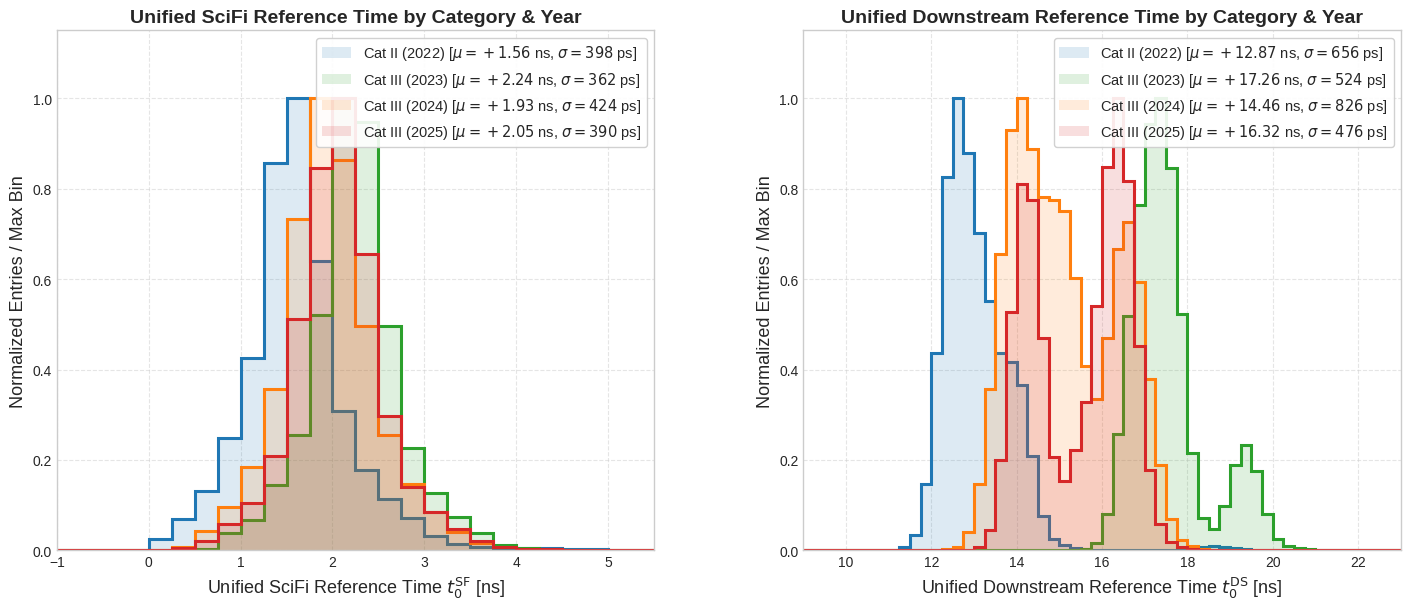

 UNIFIED REFERENCE TIME SUMMARY METRICS
 Cat II (2022)   | Runs: 33 | SF: +1.564 ns (sig= 398 ps) | DS: +12.869 ns (sig= 656 ps) | DeltaT: +11.306 ns
 Cat III (2023)  | Runs: 10 | SF: +2.237 ns (sig= 362 ps) | DS: +17.263 ns (sig= 524 ps) | DeltaT: +15.026 ns
 Cat III (2024)  | Runs: 10 | SF: +1.929 ns (sig= 424 ps) | DS: +14.456 ns (sig= 826 ps) | DeltaT: +12.527 ns
 Cat III (2025)  | Runs: 10 | SF: +2.053 ns (sig= 390 ps) | DS: +16.319 ns (sig= 476 ps) | DeltaT: +14.266 ns


In [5]:
# Define groupings for summation
groups = {
    'Cat II (2022)': {'runs': catII_runs, 'color': '#1f77b4'},
    'Cat III (2023)': {'runs': catIII_runs_by_year[2023], 'color': '#2ca02c'},
    'Cat III (2024)': {'runs': catIII_runs_by_year[2024], 'color': '#ff7f0e'},
    'Cat III (2025)': {'runs': catIII_runs_by_year[2025], 'color': '#d62728'}
}

def gaus(x, a, mu, sig):
    return a * np.exp(-0.5 * ((x - mu) / sig)**2)

def fit_hist_peak(x, y, fit_hw=1.5):
    imax = int(np.argmax(y))
    x0 = float(x[imax])
    a0 = float(y[imax])
    mask = (x >= x0 - fit_hw) & (x <= x0 + fit_hw)
    if np.count_nonzero(mask) < 4:
        return x0, 0.4
    try:
        popt, _ = curve_fit(gaus, x[mask], y[mask], p0=[a0, x0, 0.35], maxfev=2000)
        return float(popt[1]), abs(float(popt[2]))
    except Exception:
        return x0, 0.4

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))

summary_records = []

for gname, ginfo in groups.items():
    runs_in_g = [r for r in ginfo['runs'] if r in hist_data]
    if not runs_in_g:
        continue
    
    # Sum histograms
    ref_sf_edges = hist_data[runs_in_g[0]]['sf_edges']
    ref_ds_edges = hist_data[runs_in_g[0]]['ds_edges']
    
    sum_sf = np.sum([hist_data[r]['sf_val'] for r in runs_in_g], axis=0)
    sum_ds = np.sum([hist_data[r]['ds_val'] for r in runs_in_g], axis=0)
    
    bc_sf = 0.5 * (ref_sf_edges[:-1] + ref_sf_edges[1:])
    bc_ds = 0.5 * (ref_ds_edges[:-1] + ref_ds_edges[1:])
    
    # Fit peaks
    mu_sf, sig_sf = fit_hist_peak(bc_sf, sum_sf)
    mu_ds, sig_ds = fit_hist_peak(bc_ds, sum_ds)
    delta_t = mu_ds - mu_sf
    
    summary_records.append({
        'Group': gname,
        'N_Runs': len(runs_in_g),
        'Total_SF_Entries': int(np.sum(sum_sf)),
        'SF_Peak_ns': mu_sf,
        'SF_Sigma_ps': sig_sf * 1000.0,
        'Total_DS_Entries': int(np.sum(sum_ds)),
        'DS_Peak_ns': mu_ds,
        'DS_Sigma_ps': sig_ds * 1000.0,
        'Delta_t_DS_SF_ns': delta_t
    })
    
    # Normalize for overlay
    norm_sf = sum_sf / np.max(sum_sf)
    norm_ds = sum_ds / np.max(sum_ds)
    
    color = ginfo['color']
    label_sf = f"{gname} [$\mu={mu_sf:+.2f}$ ns, $\sigma={sig_sf*1000:.0f}$ ps]"
    label_ds = f"{gname} [$\mu={mu_ds:+.2f}$ ns, $\sigma={sig_ds*1000:.0f}$ ps]"
    
    ax1.stairs(norm_sf, ref_sf_edges, label=label_sf, color=color, lw=2.2, fill=True, alpha=0.15); ax1.stairs(norm_sf, ref_sf_edges, color=color, lw=2.2)
    # fill handled by stairs
    
    ax2.stairs(norm_ds, ref_ds_edges, label=label_ds, color=color, lw=2.2, fill=True, alpha=0.15); ax2.stairs(norm_ds, ref_ds_edges, color=color, lw=2.2)
    # fill handled by stairs

# SciFi Unified Plot Styling
ax1.set_xlim(-1.0, 5.5)
ax1.set_ylim(0, 1.15)
ax1.set_xlabel(r"Unified SciFi Reference Time $t_0^{\mathrm{SF}}$ [ns]", fontsize=13)
ax1.set_ylabel("Normalized Entries / Max Bin", fontsize=13)
ax1.set_title("Unified SciFi Reference Time by Category & Year", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right", fontsize=10.5, frameon=True, framealpha=0.9)

# DS Unified Plot Styling
ax2.set_xlim(9.0, 23.0)
ax2.set_ylim(0, 1.15)
ax2.set_xlabel(r"Unified Downstream Reference Time $t_0^{\mathrm{DS}}$ [ns]", fontsize=13)
ax2.set_ylabel("Normalized Entries / Max Bin", fontsize=13)
ax2.set_title("Unified Downstream Reference Time by Category & Year", fontsize=14, fontweight='bold')
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", fontsize=10.5, frameon=True, framealpha=0.9)

plt.subplots_adjust(top=0.92, bottom=0.12, left=0.07, right=0.91, wspace=0.25)
plt.show()

# Print formatted summary table
df_summary = pd.DataFrame(summary_records)
print("=" * 86)
print(" UNIFIED REFERENCE TIME SUMMARY METRICS")
print("=" * 86)
for _, row in df_summary.iterrows():
    print(f" {row['Group']:15s} | Runs: {row['N_Runs']:2d} | "
          f"SF: {row['SF_Peak_ns']:+6.3f} ns (sig={row['SF_Sigma_ps']:4.0f} ps) | "
          f"DS: {row['DS_Peak_ns']:+6.3f} ns (sig={row['DS_Sigma_ps']:4.0f} ps) | "
          f"DeltaT: {row['Delta_t_DS_SF_ns']:+6.3f} ns")
print("=" * 86)
